### Notebook behind Figure 3

This notebook was used to generate Fig 3 on the effect of $L$, the number of probe (dummy) loci. Phased (RP+mle) and unphased (RP+Burrows) were used as examples. A range of $L$ was examined, from 100 to 25,000. At each value of $L$, there are 1000 repeats. For details please see the legend of Fig 3. 

$L$ affects the precision (1/variance) of RP before it reaches a plateau after $L>=10,000$ approximately. mean is unaffected. 

In [1]:
dyn.load('../cpp/unbiased_r2_2.dll')
require(doParallel)
require(compiler)

Loading required package: doParallel

Warning message:
"package 'doParallel' was built under R version 4.5.3"
Loading required package: foreach

Warning message:
"package 'foreach' was built under R version 4.5.3"
Loading required package: iterators

Warning message:
"package 'iterators' was built under R version 4.5.3"
Loading required package: parallel

Loading required package: compiler



In [2]:
initialise<-function(N, p1=0.5, p2=0.5, D=0.1)
{
    y<-.Call('initialise2', as.integer(N), as.double(p1), as.double(p2), as.double(D))
    id<-sample(1:(2*N))
    return(y[id,])
}
# SAMPLE PHASED, WITHOUT REPLACEMENT
sample_phased<-function(y, s=50)
{
    N<-nrow(y)/2
    temp<-sample(1:N, size=s, replace=F)-1
    z<-.Call('sample_phased', y, as.integer(temp))
    return(z)
}
# SAMPLE UNPHASED, WITHOUT REPLACEMENT
sample_unphased<-function(y, s=50)
{
    N<-nrow(y)/2
    temp<-sample(1:N, size=s, replace=F)-1
    z<-.Call('sample_unphased', y, as.integer(temp))
    return(z) 
}
#

In [3]:
y<-initialise(N=10000, p1=0.6, p2=0.4, D=0.1)
true_r2<-.Call('mle_phased', as.raw(y[,1]), as.raw(y[,2]))
true_r2

[1] 0.1736111

In [4]:
# SIMULATION SETTINGS
s<-50
L<-c(100, 200, 500, 1000, 2000, 5000, 10000, 15000, 20000, 25000)
times<-1000
result<-matrix(nc=length(L), nr=times)

#### 1. Phased, RP+mle

In [5]:
cl<-makeCluster(8)
registerDoParallel(cl)
for (i in 1:length(L))
{
    temp_output<-foreach (j=1:times, .combine='c') %dopar%
    {
        if (!is.loaded('EM')) {dyn.load('../cpp/unbiased_r2_2.dll')}
        y1<-sample_phased(y, s=s)
        z<-.Call('white_noise_phased', as.integer(s), as.double(runif(L[i], 0.4, 0.6)))
        return(.Call('RG_phased_block', as.raw(y1[,1]), as.raw(y1[,2]), z, as.integer(1)))
    }
    result[,i]<-temp_output
}
stopCluster(cl)

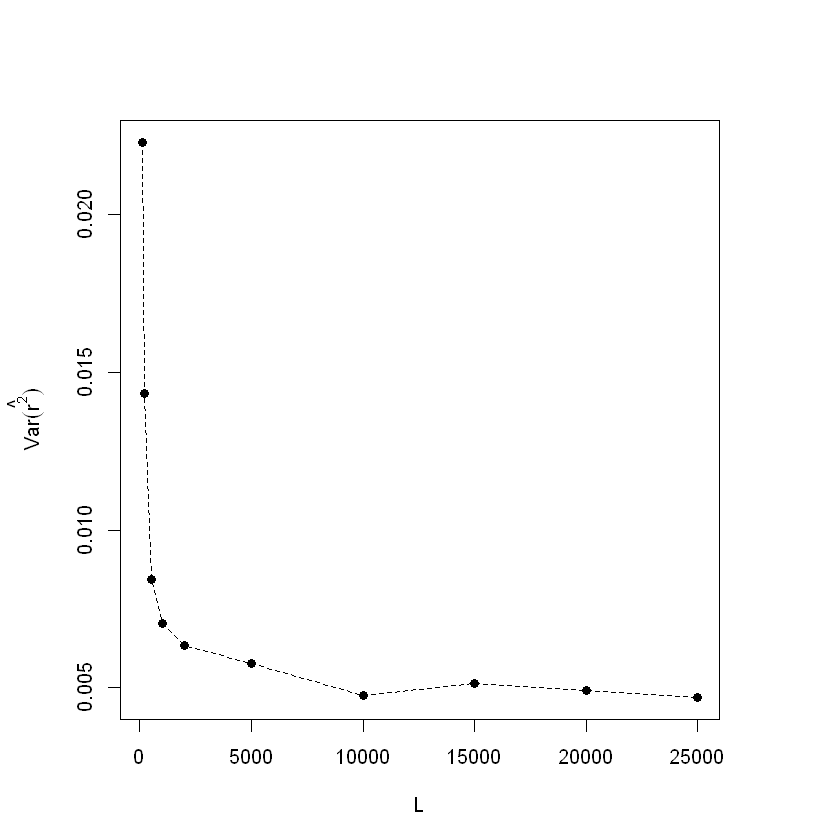

In [6]:
phased_var<-apply(result, 2, var, na.rm=T)
phased_mean<-apply(result, 2, mean, na.rm=T)
#
par(mar=c(5,5,5,5))
plot(L, phased_var, ylab=expression(Var(hat(r^2))), pch=16)
lines(L, phased_var, lty=2)

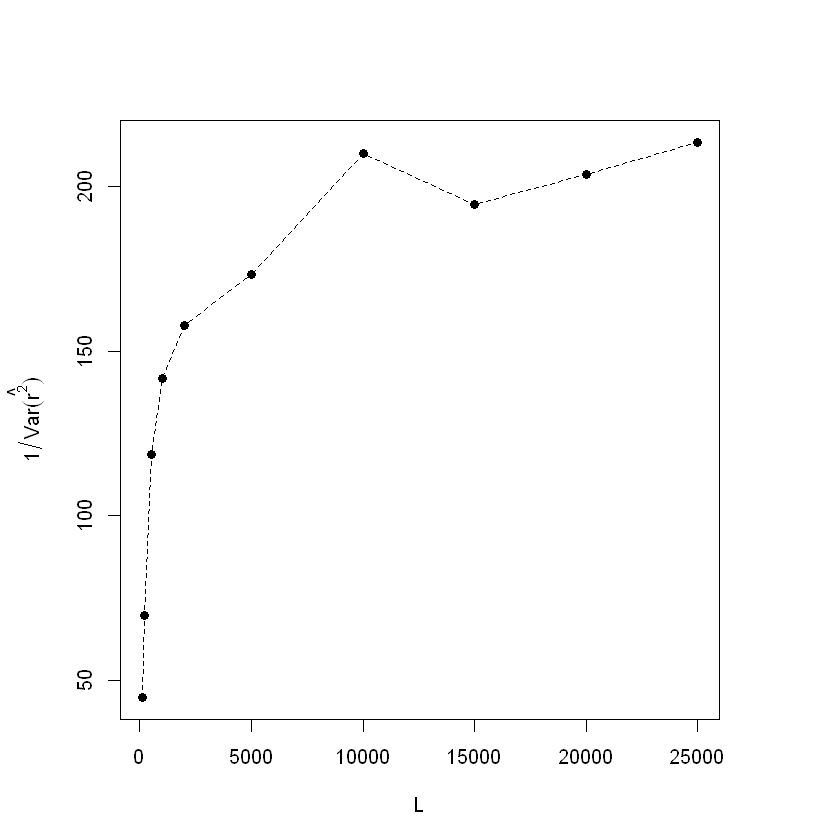

In [7]:
par(mar=c(5,5,5,5))
plot(L, 1/phased_var, ylab=expression(1/Var(hat(r^2))), pch=16)
lines(L, 1/phased_var, lty=2)

#### 2. Unphased, RP+Burrows

In [8]:
cl<-makeCluster(8)
registerDoParallel(cl)
for (i in 1:length(L))
{
    temp_output<-foreach (j=1:times, .combine='c') %dopar%
    {
        if (!is.loaded('EM')) {dyn.load('../cpp/unbiased_r2_2.dll')}
        y1<-sample_unphased(y, s=s)
        z<-.Call('white_noise_unphased', as.integer(s), as.double(runif(L[i], 0.4, 0.6)))
        return(.Call('RG_unphased_block', as.raw(y1[,1]), as.raw(y1[,2]), z, as.integer(1)))
    }
    result[,i]<-temp_output
}
stopCluster(cl)

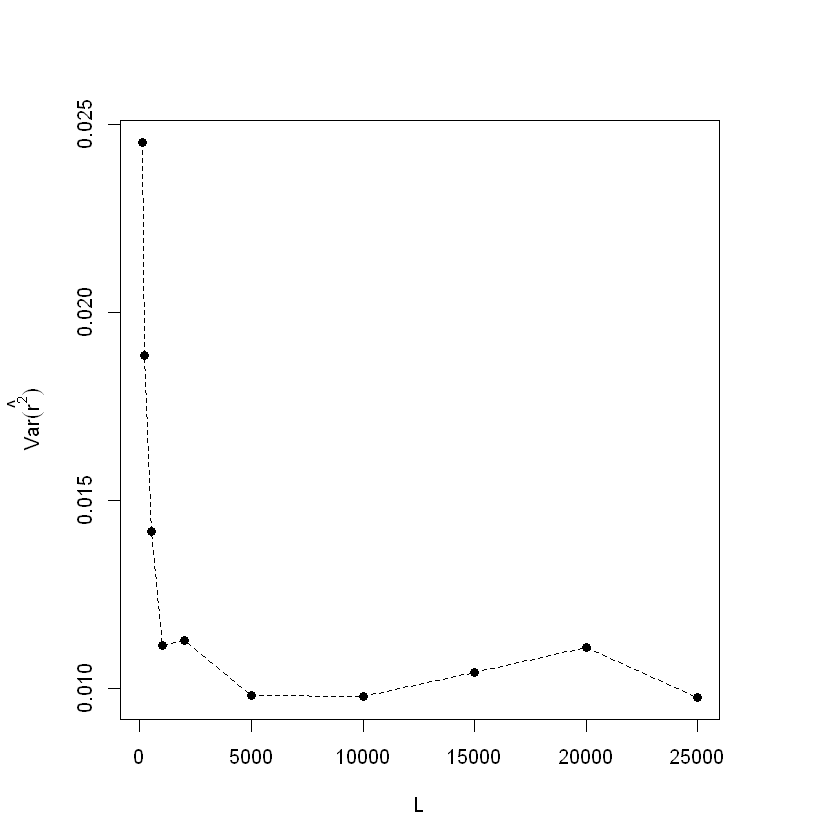

In [9]:
unphased_mean<-apply(result, 2, mean, na.rm=T)
unphased_var<-apply(result, 2, var, na.rm=T)
#
par(mar=c(5,5,5,5))
plot(L, unphased_var, ylab=expression(Var(hat(r^2))), pch=16)
lines(L, unphased_var, lty=2)


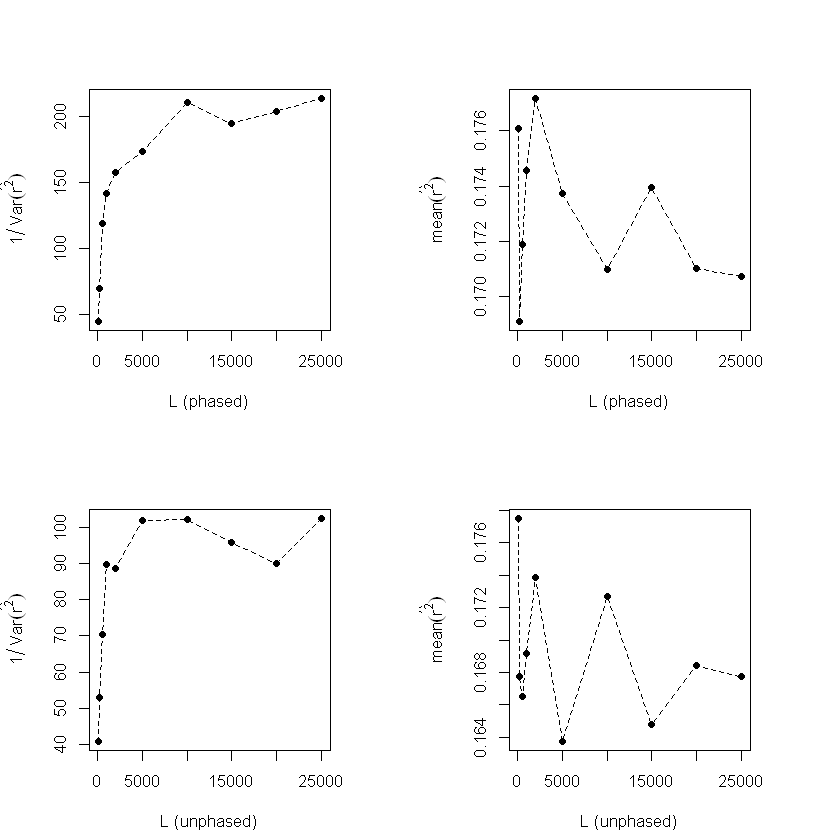

In [17]:
# ALL PLOTS TOGETHER
par(mfrow=c(2,2))
par(mar=c(4.5,4.5,4.5,4.5))
plot(L, 1/phased_var, ylab=expression(1/Var(hat(r^2))), xlab='L (phased)', pch=16)
lines(L, 1/phased_var, lty=2)
plot(L, phased_mean, ylab=expression(mean(hat(r^2))), xlab='L (phased)', pch=16)
lines(L, phased_mean, lty=2)
#
plot(L, 1/unphased_var, ylab=expression(1/Var(hat(r^2))), xlab='L (unphased)', pch=16)
lines(L, 1/unphased_var, lty=2)
plot(L, unphased_mean, ylab=expression(mean(hat(r^2))), xlab='L (unphased)', pch=16)
lines(L, unphased_mean, lty=2)

In [ ]:
dyn.unload('../cpp/unbiased_r2_2.dll')